# Historical pipeline data quality

This notebook reviews compact outputs from the resumable 2022–2024 public-data pipeline. It does not read 2025 feeds, fit a model, analyze timing, or change the frozen video gate (`validation_pending`).

In [1]:
from pathlib import Path
import platform
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
pd.set_option('display.max_columns', 30)

## Collection coverage and provenance

In [2]:
collection = pd.read_csv(RESULTS / 'historical_collection_status.csv')
runs = pd.read_csv(RESULTS / 'historical_collection_runs.csv')
schedule_provenance = pd.read_csv(DATA / 'historical_schedule_provenance.csv')
collection

,season,split_role,scheduled_regular_season_game_pks,feed_eligible_completed_games,completed_or_reused_feeds,eligible_missing_or_not_attempted,eligible_quarantined,excluded_schedule_games,excluded_quarantined_responses,bytes
0,2022,history_only,2430,2430,2430,0,0,0,0,1929493195
1,2023,training,2430,2430,2430,0,0,0,0,1950284248
2,2024,validation_development,2430,2429,2429,0,0,1,1,1939337279


In [3]:
assert collection['eligible_missing_or_not_attempted'].eq(0).all()
assert collection['eligible_quarantined'].eq(0).all()
assert collection['completed_or_reused_feeds'].equals(collection['feed_eligible_completed_games'])
assert not (DATA / 'historical_feed_manifest_2025.csv').exists()
assert set(schedule_provenance['season']) == {2022, 2023, 2024, 2025}
runs.tail(4)

,run_started_utc,run_finished_utc,wall_seconds,seasons,pilot,refresh,pace_seconds,targets,network_responses,verified_cache_reuses,failed,quarantined,bytes_available,retry_problems
0,2026-11-16T00:32:52Z,2026-11-16T00:33:35Z,42.988,2022|2023|2024,True,False,0.25,61,56,5,0,0,49428270,NaN
1,2026-11-16T00:37:28Z,2026-11-16T00:37:40Z,12.107,2022|2023|2024,True,False,0.25,61,0,61,0,0,49428270,NaN
2,2026-11-16T00:38:18Z,2026-11-16T01:51:53Z,4415.199,2022|2023|2024,False,False,0.25,7290,7023,267,0,3,5819114722,NaN
3,2026-11-16T01:53:15Z,2026-11-16T01:53:17Z,1.640,2022|2023|2024,False,False,0.25,2,2,0,0,0,1184456,True


## Pilot and full processing checks

In [4]:
pilot = pd.read_csv(RESULTS / 'historical_pilot_coverage.csv')
development = pd.read_csv(RESULTS / 'historical_development_coverage.csv')
failure_parts = [pd.read_csv(RESULTS / f'historical_development_processing_failures_{season}.csv') for season in (2022, 2023, 2024)]
failures = pd.concat(failure_parts, ignore_index=True)
validation = pd.read_csv(RESULTS / 'historical_development_validation_checks.csv')
exclusions = pd.read_csv(RESULTS / 'historical_development_exclusion_summary.csv')
history_status = pd.read_csv(RESULTS / 'historical_development_history_status.csv')
assert failures.empty
assert development['missing_games'].eq(0).all()
assert development['catcher_assignment_rate'].eq(1.0).all()
assert development['chronology_unavailable_games'].eq(0).all()
assert development['incomplete_history_rate'].eq(0).all()
assert validation['passed'].all()
pilot

,season,split_role,scheduled_eligible_games,processed_games,missing_games,quarantined_games,events,pitches,opportunities,terminal_windows,catcher_assigned_windows,unknown_action_windows,known_state_conflict_windows,attempt_history_eligible_windows,conditional_success_history_eligible_windows,pitcher_pickoff_windows,steal_attempt_windows,catcher_changed_assignment_windows,cold_start_windows,incomplete_history_windows,observed_zero_attempt_windows,observed_prior_attempt_windows,catcher_assignment_rate,cold_start_rate,incomplete_history_rate,dataset_scope
0,2022,history_only,24,24,0,0,7993,7188,1409,20,1409,0,0,1373,11,108,11,31,0,1409,0,0,1.0,0.0,1.0,pilot
1,2023,training,25,25,0,0,8445,7482,1505,30,1505,0,0,1476,20,83,20,34,0,1505,0,0,1.0,0.0,1.0,pilot
2,2024,validation_development,12,12,0,0,4136,3588,748,24,748,0,0,734,15,60,15,26,0,748,0,0,1.0,0.0,1.0,pilot


In [5]:
history_status

,season,cold_start_windows,observed_zero_attempt_windows,observed_prior_attempt_windows,incomplete_history_windows,opportunities,dataset_scope
0,2022,4167,56822,76743,0,137732,development
1,2023,728,29837,108297,0,138862,development
2,2024,630,18056,117801,0,136487,development


In [6]:
exclusions

,season,reason,windows,dataset_scope
0,2022,eligible_no_exclusion,134963,development
1,2022,runner_changed,2769,development
2,2023,eligible_no_exclusion,136310,development
3,2023,runner_changed,2552,development
4,2024,eligible_no_exclusion,133955,development
5,2024,runner_changed,2532,development


In [7]:
development

,season,split_role,scheduled_eligible_games,processed_games,missing_games,quarantined_games,chronology_unavailable_games,final_games_with_trailing_incomplete_play,events,pitches,opportunities,terminal_windows,catcher_assigned_windows,unknown_action_windows,known_state_conflict_windows,attempt_history_eligible_windows,conditional_success_history_eligible_windows,pitcher_pickoff_windows,steal_attempt_windows,catcher_changed_assignment_windows,cold_start_windows,incomplete_history_windows,observed_zero_attempt_windows,observed_prior_attempt_windows,catcher_assignment_rate,cold_start_rate,incomplete_history_rate,dataset_scope
0,2022,history_only,2430,2430,0,0,0,2,781319,708540,137732,3135,137732,0,0,134963,1796,11524,1797,3558,4167,0,56822,76743,1.0,0.030254,0.0,development
1,2023,training,2430,2430,0,0,0,0,818768,717945,138862,3828,138862,0,0,136310,2377,7479,2377,3722,728,0,29837,108297,1.0,0.005243,0.0,development
2,2024,validation_development,2429,2429,0,1,0,0,816024,709512,136487,3911,136487,0,0,133955,2462,7633,2462,3172,630,0,18056,117801,1.0,0.004616,0.0,development


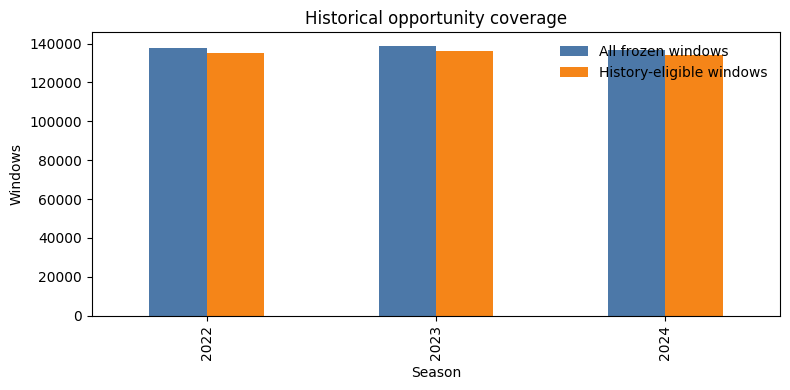

In [8]:
plot_data = development.set_index('season')[['opportunities', 'attempt_history_eligible_windows']]
ax = plot_data.plot.bar(figsize=(8, 4), color=['#4C78A8', '#F58518'])
ax.set(title='Historical opportunity coverage', ylabel='Windows', xlabel='Season')
ax.legend(['All frozen windows', 'History-eligible windows'], frameon=False)
plt.tight_layout()
plt.show()

## Environment and scope checks

The checks below confirm that 2025 remains schedule-only and the timing gate remains pending. The historical tables are suitable for later forward-only exploratory feature construction; they do not authorize model fitting in this task.

In [9]:
environment = pd.read_csv(RESULTS / 'historical_development_environment.csv')
assert environment.set_index('item').loc['video_gate', 'value'] == 'validation_pending'
pd.DataFrame({'item': ['python', 'pandas', 'numpy', 'matplotlib', '2025_feed_manifest_exists'], 'value': [platform.python_version(), pd.__version__, np.__version__, matplotlib.__version__, (DATA / 'historical_feed_manifest_2025.csv').exists()]})

,item,value
0,python,3.14.4
1,pandas,3.0.2
2,numpy,2.4.4
3,matplotlib,3.10.8
4,2025_feed_manifest_exists,False
